<a href="https://colab.research.google.com/github/Joe-Something/AAI2026/blob/main/InventoryReplenishmentAgent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inventory Replenishment Agent

A small, fully reproducible replenishment agent for 3 SKUs over a 120-day demand history.

**Pipeline**

1. **Data**: load (or auto-generate) `sales.csv`, `inventory.csv`, `params.csv`; aggregate transactions to daily demand per SKU.
2. **Forecast**: per-SKU EWMA (smoothing factor tuned on a warm-up window), compared against a naive "tomorrow = today" forecast.
3. **Safety stock**: from the rolling one-step forecast error and each SKU's `service_level`.
4. **Agent loop**: every review the agent projects on-hand inventory over the *lead time + review period*, then either **ORDERs** (respecting `min_order_qty`) or **WAITs** (to avoid holding cost), and writes down why.
5. **Simulation & evaluation**: POs arrive after the lead time; we track stockouts, fill rate and holding, stockout and ordering costs, and compare the agent against simpler policies.

**Timeline convention.** The first `WARMUP_DAYS` of sales are treated as history the agent can learn from. `opening_stock` is the stock on hand at the start of the simulated horizon (the remaining days).

**Running it.** Works locally or in Google Colab (*File, Upload notebook*, then *Runtime, Run all*). The CSVs are generated into `data/` on first run, so no uploads are needed. The only dependencies are `numpy`, `pandas` and `matplotlib`, all preinstalled in Colab. The optional Gemini step (Section 8) reads the `GEMINI_API_KEY` secret.

## 0. Setup & configuration

In [1]:
import itertools
import math
import os
import subprocess
import sys
from collections import deque
from dataclasses import asdict, dataclass
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

IN_COLAB = "google.colab" in sys.modules
print("Running in Google Colab" if IN_COLAB else "Running locally")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

SEED = 42
N_DAYS = 120               # length of the sales history
START_DATE = "2025-01-01"
WARMUP_DAYS = 30           # history used to tune/initialise the forecaster before the simulation starts
REVIEW_PERIOD_DAYS = 1     # R: how often the agent reviews (1 = daily)
ORDER_COST_PER_PO = 25.0   # fixed cost per purchase order (set to 0.0 to ignore ordering cost)
ERROR_WINDOW = 28          # days of one-step forecast errors used to estimate sigma
REGENERATE_DATA = False    # True = overwrite the CSVs with fresh synthetic data

Running in Google Colab


## 1. Data: generate (if missing) and load

The generator creates three SKUs with deliberately different behaviour, so the agent has something to reason about:

| SKU | Demand pattern | Lead time | MOQ | Service level |
|---|---|---|---|---|
| SKU-A | steady, high volume (~40/day) | 5 d | 150 | 95% |
| SKU-B | weekly seasonality (busy weekends) + upward trend | 7 d | 100 | 97% |
| SKU-C | low volume, Poisson, with promo spikes | 10 d | 60 | 90% |

`sales.csv` is written as a *transaction log* (1–3 rows per SKU per day, zero-sales days omitted), so it has to be aggregated and gap-filled, as real POS extracts usually do. If you already have your own three CSVs in `data/`, they are used as-is.

In [2]:
def make_synthetic_data(n_days: int = N_DAYS, start: str = START_DATE, seed: int = SEED):
    """Returns (sales, inventory, params) DataFrames in the three CSV schemas."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, periods=n_days, freq="D")
    t = np.arange(n_days)
    dow = dates.day_of_week.to_numpy()

    # SKU-A: steady, high volume
    a = rng.normal(40, 6, n_days)
    # SKU-B: weekly seasonality (weekends +45%) on a mild upward trend
    b = (22 + 0.08 * t) * np.where(dow >= 5, 1.45, 1.0) + rng.normal(0, 3, n_days)
    # SKU-C: low-volume Poisson demand with a handful of promo spikes
    c = rng.poisson(7, n_days).astype(float)
    promo_days = rng.choice(n_days, size=6, replace=False)
    c[promo_days] *= rng.uniform(2.5, 4.0, size=6)

    rows = []
    for sku, qty in {"SKU-A": a, "SKU-B": b, "SKU-C": c}.items():
        qty = np.clip(np.round(qty), 0, None).astype(int)
        for day, q in zip(dates, qty):
            if q == 0:
                continue  # zero-sales days are simply absent from a transaction log
            # split the day's demand into 1-3 transactions so the file needs aggregating
            n_tx = int(min(q, rng.integers(1, 4)))
            cuts = np.sort(rng.choice(np.arange(1, q), size=n_tx - 1, replace=False)) if n_tx > 1 else np.array([], dtype=int)
            for part in np.diff(np.concatenate([[0], cuts, [q]])):
                rows.append((day, sku, int(part)))
    sales = pd.DataFrame(rows, columns=["date", "sku", "qty_sold"])

    inventory = pd.DataFrame({
        "sku": ["SKU-A", "SKU-B", "SKU-C"],
        "opening_stock": [300, 220, 50],
    })

    params = pd.DataFrame({
        "sku": ["SKU-A", "SKU-B", "SKU-C"],
        "unit_cost": [12.0, 30.0, 55.0],
        "holding_cost_per_day": [0.03, 0.08, 0.15],   # per unit per day (~25-100%/yr of unit cost)
        "stockout_cost": [5.0, 12.0, 25.0],           # per unit of lost sales
        "lead_time_days": [5, 7, 10],
        "min_order_qty": [150, 100, 60],
        "service_level": [0.95, 0.97, 0.90],
    })
    return sales, inventory, params


def generate_data(data_dir: Path, seed: int = SEED) -> None:
    sales, inventory, params = make_synthetic_data(seed=seed)
    sales.to_csv(data_dir / "sales.csv", index=False, date_format="%Y-%m-%d")
    inventory.to_csv(data_dir / "inventory.csv", index=False)
    params.to_csv(data_dir / "params.csv", index=False)


files = [DATA_DIR / f for f in ("sales.csv", "inventory.csv", "params.csv")]
if REGENERATE_DATA or not all(f.exists() for f in files):
    generate_data(DATA_DIR)
    print("Generated synthetic data in", DATA_DIR.resolve())
else:
    print("Using existing CSVs in", DATA_DIR.resolve())

Generated synthetic data in /content/data


In [3]:
sales_raw = pd.read_csv(DATA_DIR / "sales.csv", parse_dates=["date"])
inventory = pd.read_csv(DATA_DIR / "inventory.csv")
params = pd.read_csv(DATA_DIR / "params.csv").set_index("sku")

# --- validation ---------------------------------------------------------------
assert {"date", "sku", "qty_sold"} <= set(sales_raw.columns), "sales.csv schema mismatch"
assert (sales_raw["qty_sold"] >= 0).all(), "negative sales found"
assert params["service_level"].between(0.5, 0.9999).all(), "service_level must be in (0.5, 1)"
missing_params = set(sales_raw["sku"]) - set(params.index)
missing_stock = set(params.index) - set(inventory["sku"])
assert not missing_params, f"SKUs without params: {missing_params}"
assert not missing_stock, f"SKUs without opening stock: {missing_stock}"

SKUS = list(params.index)
print(f"sales.csv: {len(sales_raw):,} transaction rows, {sales_raw['date'].min():%Y-%m-%d} to {sales_raw['date'].max():%Y-%m-%d}")
display(sales_raw.head())
display(inventory)
display(params)

sales.csv: 718 transaction rows, 2025-01-01 to 2025-04-30


,date,sku,qty_sold
0,2025-01-01,SKU-A,19
1,2025-01-01,SKU-A,5
2,2025-01-01,SKU-A,18
3,2025-01-02,SKU-A,3
4,2025-01-02,SKU-A,25


,sku,opening_stock
0,SKU-A,300
1,SKU-B,220
2,SKU-C,50


,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
sku,,,,,,
SKU-A,12.0,0.03,5.0,5,150,0.95
SKU-B,30.0,0.08,12.0,7,100,0.97
SKU-C,55.0,0.15,25.0,10,60,0.90


### Task 1: aggregate to daily demand per SKU

Sum transactions per `(date, sku)`, pivot to one column per SKU, and reindex to a complete calendar so days with no sales become explicit zeros.

Daily demand matrix: 120 days x 3 SKUs (0 SKU-days had no sales and were zero-filled)


,count,mean,std,min,25%,50%,75%,max
sku,,,,,,,,
SKU-A,120.0,39.6,4.8,28.0,36.8,40.0,43.0,53.0
SKU-B,120.0,30.0,6.7,17.0,25.0,29.0,34.0,46.0
SKU-C,120.0,7.6,3.5,1.0,5.0,7.0,9.0,22.0


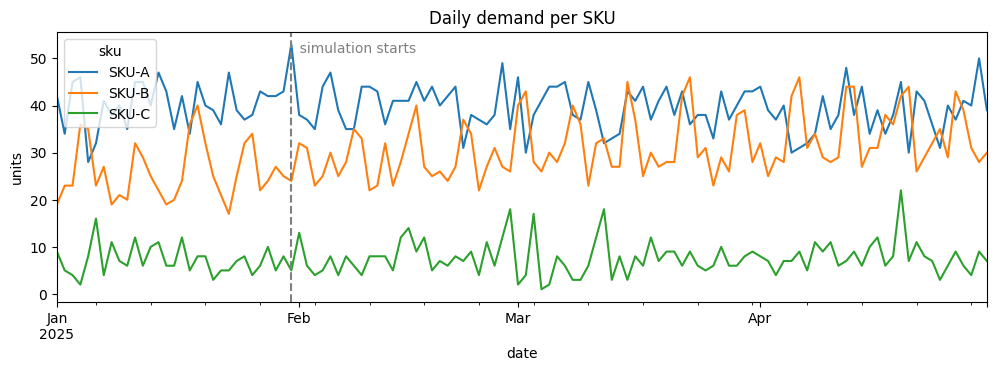

In [4]:
def aggregate_daily(sales: pd.DataFrame, skus: list) -> pd.DataFrame:
    """Transactions -> one row per calendar day, one column per SKU (NaN where nothing sold)."""
    dates = pd.to_datetime(sales["date"])
    full_calendar = pd.date_range(dates.min(), dates.max(), freq="D", name="date")
    return (
        sales.assign(date=dates)
        .groupby(["date", "sku"])["qty_sold"].sum()
        .unstack("sku")
        .reindex(index=full_calendar, columns=skus)
    )


demand = aggregate_daily(sales_raw, SKUS)
zero_filled = int(demand.isna().sum().sum())
demand = demand.fillna(0).astype(int)

print(f"Daily demand matrix: {demand.shape[0]} days x {demand.shape[1]} SKUs ({zero_filled} SKU-days had no sales and were zero-filled)")
display(demand.describe().T.round(1))

ax = demand.plot(figsize=(12, 3.5), title="Daily demand per SKU")
ax.axvline(demand.index[WARMUP_DAYS], color="grey", ls="--")
ax.text(demand.index[WARMUP_DAYS], ax.get_ylim()[1] * 0.92, "  simulation starts", color="grey")
ax.set_ylabel("units");

## 2. Demand forecast: EWMA vs naive

**EWMA**: $\ell_t = \alpha d_t + (1-\alpha)\,\ell_{t-1}$, and the forecast for every future day is the current level $\ell_t$ (a flat daily rate).
**Naive**: tomorrow = today, which is just EWMA with $\alpha = 1$.

$\alpha$ is tuned per SKU on the warm-up window only, by minimising one-step-ahead MSE over a grid, so the simulated horizon stays out-of-sample.

In [5]:
INIT_DAYS = 7  # the first level is the mean of the first week
ALPHA_GRID = np.round(np.arange(0.05, 0.65, 0.05), 2)


def one_step_forecasts(series: np.ndarray, alpha: float, init: int = INIT_DAYS) -> np.ndarray:
    """Forecast for day t made at the end of day t-1, for t = init .. n-1."""
    level = series[:init].mean()
    out = []
    for d in series[init:]:
        out.append(level)
        level = alpha * d + (1 - alpha) * level
    return np.array(out)


def tune_alpha(history: np.ndarray) -> float:
    mse = {a: np.mean((history[INIT_DAYS:] - one_step_forecasts(history, a)) ** 2) for a in ALPHA_GRID}
    return float(min(mse, key=mse.get))


class EWMAForecaster:
    """Online EWMA level with a rolling RMSE of one-step-ahead errors (used for safety stock)."""

    def __init__(self, alpha: float, error_window: int = ERROR_WINDOW):
        self.alpha = alpha
        self.level = None
        self.errors = deque(maxlen=error_window)

    @classmethod
    def from_history(cls, history: np.ndarray, alpha: float, error_window: int = ERROR_WINDOW):
        f = cls(alpha, error_window)
        f.level = float(history[:INIT_DAYS].mean())
        for d in history[INIT_DAYS:]:
            f.update(d)
        return f

    def update(self, actual: float) -> None:
        self.errors.append(actual - self.level)
        self.level = self.alpha * actual + (1 - self.alpha) * self.level

    @property
    def rate(self) -> float:
        """Forecast daily demand."""
        return max(self.level, 0.0)

    @property
    def sigma(self) -> float:
        """Daily forecast-error standard deviation (RMSE, so persistent bias is penalised too)."""
        if len(self.errors) < 2:
            return math.sqrt(max(self.level, 1.0))  # Poisson-style fallback
        e = np.asarray(self.errors)
        return float(np.sqrt(np.mean(e ** 2)))


history = demand.iloc[:WARMUP_DAYS]
alphas = {sku: tune_alpha(history[sku].to_numpy()) for sku in SKUS}
print("Tuned alpha per SKU:", alphas)

Tuned alpha per SKU: {'SKU-A': 0.1, 'SKU-B': 0.05, 'SKU-C': 0.05}


alpha   MAE  RMSE  bias  MAPE_%
sku   model                                 
SKU-A EWMA    0.10  4.01  4.89 -0.14   10.16
      Naive   1.00  5.20  6.56 -0.04   13.18
SKU-B EWMA    0.05  4.97  6.30  1.56   15.81
      Naive   1.00  5.94  7.65  0.06   18.91
SKU-C EWMA    0.05  2.71  3.68  0.18   35.32
      Naive   1.00  3.92  5.25 -0.01   51.09

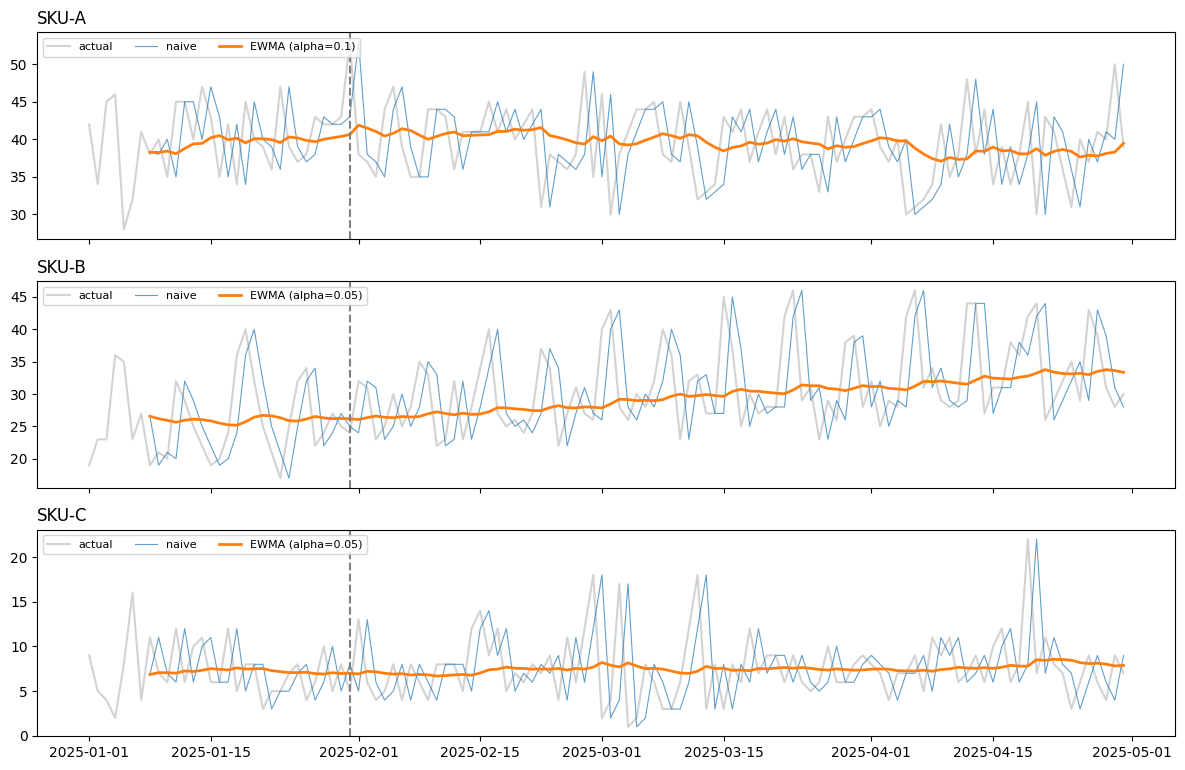

In [6]:
# Out-of-sample accuracy on the simulation horizon (forecasts made one day ahead)
rows = []
for sku in SKUS:
    s = demand[sku].to_numpy().astype(float)
    actual = s[INIT_DAYS:]
    for name, a in [("EWMA", alphas[sku]), ("Naive", 1.0)]:
        err = (actual - one_step_forecasts(s, a))[WARMUP_DAYS - INIT_DAYS:]
        rows.append({"sku": sku, "model": name, "alpha": a,
                     "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "bias": err.mean(),
                     "MAPE_%": 100 * np.abs(err).sum() / actual[WARMUP_DAYS - INIT_DAYS:].sum()})
accuracy = pd.DataFrame(rows).set_index(["sku", "model"])
display(accuracy.round(2))

fig, axes = plt.subplots(len(SKUS), 1, figsize=(12, 2.6 * len(SKUS)), sharex=True)
for ax, sku in zip(axes, SKUS):
    s = demand[sku]
    idx = s.index[INIT_DAYS:]
    ax.plot(s.index, s, color="lightgrey", label="actual")
    ax.plot(idx, one_step_forecasts(s.to_numpy().astype(float), 1.0), lw=0.8, alpha=0.7, label="naive")
    ax.plot(idx, one_step_forecasts(s.to_numpy().astype(float), alphas[sku]), lw=2, label=f"EWMA (alpha={alphas[sku]})")
    ax.axvline(s.index[WARMUP_DAYS], color="grey", ls="--")
    ax.set_title(sku, loc="left")
    ax.legend(loc="upper left", ncol=3, fontsize=8)
plt.tight_layout()

## 3. Safety stock from forecast error and service level

The agent can only change what arrives after the lead time, and it only looks again after the review period, so the uncertainty it must buffer is the forecast error over the **protection period** $P = L + R$:

$$SS = z_{\text{service level}} \cdot \sigma_{e} \cdot \sqrt{L + R}$$

where $\sigma_e$ is the rolling RMSE of one-step forecast errors (assumed independent day to day) and $z$ is the standard-normal quantile of the target cycle service level. The **order trigger** in inventory-position terms is $\hat\mu \cdot (L+R) + SS$.

Below are the values at the start of the simulation. The agent recomputes them every day as the forecast and the error estimate update.

In [7]:
def z_value(service_level: float) -> float:
    return NormalDist().inv_cdf(service_level)


def safety_stock(sigma_daily: float, lead_time: int, review_period: int, service_level: float) -> float:
    return z_value(service_level) * sigma_daily * math.sqrt(lead_time + review_period)


rows = []
for sku in SKUS:
    p = params.loc[sku]
    f = EWMAForecaster.from_history(history[sku].to_numpy().astype(float), alphas[sku])
    L, R = int(p.lead_time_days), REVIEW_PERIOD_DAYS
    ss = safety_stock(f.sigma, L, R, p.service_level)
    rows.append({"sku": sku, "alpha": alphas[sku], "forecast/day": f.rate, "sigma/day": f.sigma,
                 "service_level": p.service_level, "z": z_value(p.service_level), "L+R": L + R,
                 "safety_stock": ss, "order_trigger (IP)": f.rate * (L + R) + ss,
                 "opening_stock": int(inventory.set_index("sku").loc[sku, "opening_stock"]),
                 "days_of_cover": inventory.set_index("sku").loc[sku, "opening_stock"] / f.rate})
display(pd.DataFrame(rows).set_index("sku").round(2))

,alpha,forecast/day,sigma/day,service_level,z,L+R,safety_stock,order_trigger (IP),opening_stock,days_of_cover
sku,,,,,,,,,,
SKU-A,0.10,40.65,4.07,0.95,1.64,6,16.40,260.29,300,7.38
SKU-B,0.05,26.17,6.15,0.97,1.88,8,32.69,242.03,220,8.41
SKU-C,0.05,7.02,2.61,0.90,1.28,11,11.07,88.24,50,7.13


## 4. The replenishment agent

At the end of each review day the agent runs **observe, forecast, project, decide, explain**:

1. **Observe** on-hand stock and the open POs in the pipeline (quantity and arrival date).
2. **Forecast** the daily rate $\hat\mu$ and the error $\sigma_e$, then compute $SS$.
3. **Project** on-hand inventory day by day over the next $L+R$ days, using the forecast and the *scheduled* PO receipts.
4. **Decide**. Split the projection in two:
   - *Days 1..L are locked in.* A PO placed now cannot land before then. A stockout projected there is flagged as a **WARNING** (it would need an expedite), but it does **not** trigger another regular order. Reacting to it would stack PO after PO that all arrive too late.
   - *Days L+1..L+R are the days today's PO can protect.* If projected stock there stays at or above $SS$, **WAIT**: ordering now would only bring stock in early and add holding cost, and the next review can still react in time.
   - Otherwise **ORDER**: $Q = \max(\lceil S - IP \rceil,\ \text{MOQ},\ \text{EOQ})$, where $S = \hat\mu(L+R) + SS$ is the order-up-to level and $\text{EOQ} = \sqrt{2K\hat\mu / h}$ balances the fixed PO cost $K$ against holding cost (EOQ = 0 when $K = 0$). Checking the projection on day $L+R$ is equivalent to the classic test $IP < \hat\mu(L+R) + SS$.
5. **Explain**: every decision carries a human-readable rationale with the numbers behind it.

**Event order within a day:** demand is served from on-hand stock (unmet demand is *lost*), then POs due that day are received, then the agent reviews. A PO placed at the end of day $t$ arrives at the end of day $t+L$ and can serve demand from day $t+L+1$.

In [8]:
@dataclass
class PurchaseOrder:
    po_id: int
    sku: str
    qty: int
    placed: pd.Timestamp
    arrives: pd.Timestamp


@dataclass
class Decision:
    date: pd.Timestamp
    sku: str
    action: str            # "ORDER" or "WAIT"
    qty: int
    on_hand: float
    on_order: float
    inv_position: float    # before this decision's order
    forecast: float
    sigma: float
    safety_stock: float
    order_trigger: float   # mu*(L+R) + SS, in inventory-position terms
    projected_min: float         # lowest projected on-hand over the next L+R days, with no new order
    projected_at_arrival: float  # lowest projected on-hand on days L+1..L+R (the days a new PO can protect)
    stockout_in_days: object     # days until a stockout that falls inside the lead time, else None
    rationale: str


class ReplenishmentAgent:
    def __init__(self, sku: str, p: pd.Series, forecaster: EWMAForecaster,
                 review_period: int = 1, order_cost: float = 0.0, use_safety_stock: bool = True):
        self.sku = sku
        self.forecaster = forecaster
        self.L = int(p.lead_time_days)
        self.R = int(review_period)
        self.moq = int(p.min_order_qty)
        self.service_level = float(p.service_level)
        self.h = float(p.holding_cost_per_day)
        self.order_cost = float(order_cost)
        self.use_safety_stock = use_safety_stock

    def observe_demand(self, qty: int) -> None:
        self.forecaster.update(qty)

    def _project(self, date, on_hand, pipeline, mu, horizon):
        """Projected on-hand after each future day's demand (before that day's receipts)."""
        level, path = float(on_hand), []
        for k in range(1, horizon + 1):
            day = date + pd.Timedelta(days=k)
            level -= mu
            path.append(level)
            level += sum(po.qty for po in pipeline if po.arrives == day)
        return path

    def decide(self, day_idx: int, date: pd.Timestamp, on_hand: float, pipeline: list) -> Decision:
        mu, sigma = self.forecaster.rate, self.forecaster.sigma
        P = self.L + self.R
        ss = safety_stock(sigma, self.L, self.R, self.service_level) if self.use_safety_stock else 0.0
        on_order = sum(po.qty for po in pipeline)
        ip = on_hand + on_order
        trigger = mu * P + ss

        path = self._project(date, on_hand, pipeline, mu, P)
        # Days 1..L are locked in: a PO placed today lands at the end of day L. It can only protect
        # days L+1..L+R; after that, the PO from the next review takes over.
        locked, reachable = path[:self.L], path[self.L:]
        reachable_min = min(reachable)
        stockout_k = next((k for k, v in enumerate(locked, 1) if v < 0), None)
        state = dict(date=date, sku=self.sku, on_hand=on_hand, on_order=on_order, inv_position=ip,
                     forecast=mu, sigma=sigma, safety_stock=ss, order_trigger=trigger,
                     projected_min=min(path), projected_at_arrival=reachable_min, stockout_in_days=stockout_k)

        if day_idx % self.R != 0:
            return Decision(action="WAIT", qty=0, rationale="Not a review day.", **state)

        window = f"day {self.L + 1}" if self.R == 1 else f"days {self.L + 1}-{P}"
        risk = ""
        if stockout_k is not None:
            risk = (f" WARNING: stockout projected in {stockout_k}d, inside the {self.L}d lead time; "
                    f"no new PO can land in time (would need an expedite).")

        if reachable_min >= ss:
            cover = on_hand / mu if mu > 0 else float("inf")
            return Decision(
                action="WAIT", qty=0, **state,
                rationale=(f"On {window}, when a PO placed today would land, projected stock is {reachable_min:.0f} >= SS {ss:.0f} "
                           f"(IP {ip:.0f} >= trigger {trigger:.0f}); {cover:.1f}d of cover on hand. "
                           f"Waiting avoids holding cost (~${self.moq * self.h:.2f}/day for each MOQ that arrives early).{risk}"))

        target = trigger  # order-up-to level S
        need = max(0, math.ceil(target - ip))
        eoq = math.ceil(math.sqrt(2 * self.order_cost * mu / self.h)) if self.order_cost > 0 and mu > 0 else 0
        qty = max(need, self.moq, eoq)
        binding = {need: "need", self.moq: "MOQ", eoq: "EOQ"}[qty]
        arrival = date + pd.Timedelta(days=self.L)

        why = (f"Without an order, stock on {window} is projected at {reachable_min:.0f} < SS {ss:.0f}"
               f"{' (a stockout)' if reachable_min < 0 else ''}; IP {ip:.0f} < trigger {trigger:.0f} = {mu:.1f}/d x {P}d + SS. "
               f"Order {qty} = max(need {need}, MOQ {self.moq}, EOQ {eoq}) [{binding} binds], "
               f"arrives {arrival:%m-%d}.{risk}")
        return Decision(action="ORDER", qty=qty, rationale=why, **state)

## 5. Simulation

Runs the agents over the horizon. Each day it records demand, units served and lost, receipts, end-of-day stock, and costs:

* **Holding** = `holding_cost_per_day` × end-of-day on-hand
* **Stockout** = `stockout_cost` × lost units
* **Ordering** = `ORDER_COST_PER_PO` per PO placed
* Purchase spend (`unit_cost` × qty) is reported separately. Every policy has to buy roughly the same units, so it is not part of the *relevant* total cost.

In [9]:
@dataclass
class SimResult:
    daily: pd.DataFrame
    decisions: pd.DataFrame
    purchase_orders: pd.DataFrame


def ewma_factory(sku, hist):
    return EWMAForecaster.from_history(hist, tune_alpha(hist))  # alpha tuned on this run's warm-up only


def naive_factory(sku, hist):
    return EWMAForecaster.from_history(hist, 1.0)


def simulate(demand, params, inventory, warmup=WARMUP_DAYS, forecaster_factory=ewma_factory,
             review_period=REVIEW_PERIOD_DAYS, order_cost=ORDER_COST_PER_PO, use_safety_stock=True) -> SimResult:
    hist, horizon = demand.iloc[:warmup], demand.iloc[warmup:]
    agents = {sku: ReplenishmentAgent(sku, params.loc[sku],
                                      forecaster_factory(sku, hist[sku].to_numpy().astype(float)),
                                      review_period, order_cost, use_safety_stock)
              for sku in SKUS}
    on_hand = {sku: int(q) for sku, q in inventory.set_index("sku")["opening_stock"].items()}
    pipeline = {sku: [] for sku in SKUS}
    po_ids = itertools.count(1)
    daily, decisions, pos = [], [], []

    for i, (date, row) in enumerate(horizon.iterrows()):
        for sku in SKUS:
            p, agent = params.loc[sku], agents[sku]
            d = int(row[sku])

            served = min(on_hand[sku], d)                        # 1) serve demand, lost sales if short
            lost = d - served
            on_hand[sku] -= served

            arriving = [po for po in pipeline[sku] if po.arrives == date]   # 2) receive POs due today
            received = sum(po.qty for po in arriving)
            pipeline[sku] = [po for po in pipeline[sku] if po.arrives != date]
            on_hand[sku] += received

            agent.observe_demand(d)                              # 3) learn, then review
            dec = agent.decide(i, date, on_hand[sku], pipeline[sku])
            if dec.action == "ORDER":
                po = PurchaseOrder(next(po_ids), sku, dec.qty, date, date + pd.Timedelta(days=agent.L))
                pipeline[sku].append(po)
                pos.append(po)

            on_order = sum(po.qty for po in pipeline[sku])
            daily.append({
                "date": date, "sku": sku, "demand": d, "served": served, "lost": lost,
                "received": received, "on_hand_end": on_hand[sku], "on_order": on_order,
                "inv_position": on_hand[sku] + on_order, "ordered": dec.qty,
                "holding_cost": on_hand[sku] * p.holding_cost_per_day,
                "stockout_cost": lost * p.stockout_cost,
                "order_cost": order_cost if dec.qty > 0 else 0.0,
                "purchase_spend": dec.qty * p.unit_cost,
            })
            decisions.append(dec)

    return SimResult(pd.DataFrame(daily), pd.DataFrame([asdict(d) for d in decisions]),
                     pd.DataFrame([asdict(po) for po in pos]))


def kpis(daily: pd.DataFrame) -> pd.DataFrame:
    g = daily.groupby("sku")
    n_days = daily["date"].nunique()
    out = pd.DataFrame({
        "demand": g["demand"].sum(),
        "served": g["served"].sum(),
        "lost_units": g["lost"].sum(),
        "stockout_days": g["lost"].apply(lambda x: int((x > 0).sum())),
        "n_POs": g["ordered"].apply(lambda x: int((x > 0).sum())),
        "avg_on_hand": g["on_hand_end"].mean(),
        "holding_cost": g["holding_cost"].sum(),
        "stockout_cost": g["stockout_cost"].sum(),
        "order_cost": g["order_cost"].sum(),
        "purchase_spend": g["purchase_spend"].sum(),
    })
    out.loc["TOTAL"] = out.sum()
    out["fill_rate"] = out["served"] / out["demand"]
    out["cycle_service"] = 1 - out["stockout_days"] / n_days
    out.loc["TOTAL", "cycle_service"] = 1 - out.loc["TOTAL", "stockout_days"] / (n_days * len(SKUS))
    out["total_cost"] = out[["holding_cost", "stockout_cost", "order_cost"]].sum(axis=1)
    cols = ["demand", "served", "lost_units", "fill_rate", "stockout_days", "cycle_service", "n_POs",
            "avg_on_hand", "holding_cost", "stockout_cost", "order_cost", "total_cost", "purchase_spend"]
    return out[cols]


result = simulate(demand, params, inventory)
print(f"Simulated {result.daily['date'].nunique()} days "
      f"({result.daily['date'].min():%Y-%m-%d} to {result.daily['date'].max():%Y-%m-%d}), "
      f"{len(result.purchase_orders)} POs placed.")

Simulated 90 days (2025-01-31 to 2025-04-30), 48 POs placed.


## 6. Daily agent log (Task 6)

One line per SKU per day: the action, the state the agent saw (OH = on hand, OO = on order, IP = inventory position), the forecast, the safety stock, and the rationale. The full log is also saved to `data/agent_log.csv`.

In [10]:
def print_agent_log(decisions: pd.DataFrame, skus=None, only_orders=False) -> None:
    log = decisions if skus is None else decisions[decisions["sku"].isin(skus)]
    if only_orders:
        log = log[log["action"] == "ORDER"]
    for date, day in log.groupby("date"):
        print(f"--- {date:%Y-%m-%d} ({date:%a}) ---")
        for r in day.itertuples():
            act = f"{r.action} {r.qty}" if r.qty else r.action
            print(f"  {r.sku:<6} {act:<10} | OH {r.on_hand:>4.0f}  OO {r.on_order:>4.0f}  IP {r.inv_position:>4.0f} "
                  f"| fcst {r.forecast:5.1f}/d  sd {r.sigma:4.1f}  SS {r.safety_stock:4.0f} | {r.rationale}")


result.decisions.to_csv(DATA_DIR / "agent_log.csv", index=False)
print_agent_log(result.decisions)

--- 2025-01-31 (Fri) ---
  SKU-A  ORDER 265  | OH  247  OO    0  IP  247 | fcst  41.9/d  sd  4.7  SS   19 | Without an order, stock on day 6 is projected at -4 < SS 19 (a stockout); IP 247 < trigger 270 = 41.9/d x 6d + SS. Order 265 = max(need 24, MOQ 150, EOQ 265) [EOQ binds], arrives 02-05.
  SKU-B  ORDER 128  | OH  196  OO    0  IP  196 | fcst  26.1/d  sd  6.0  SS   32 | Without an order, stock on day 8 is projected at -12 < SS 32 (a stockout); IP 196 < trigger 241 = 26.1/d x 8d + SS. Order 128 = max(need 45, MOQ 100, EOQ 128) [EOQ binds], arrives 02-07.
  SKU-C  ORDER 60   | OH   45  OO    0  IP   45 | fcst   6.9/d  sd  2.6  SS   11 | Without an order, stock on day 11 is projected at -31 < SS 11 (a stockout); IP 45 < trigger 87 = 6.9/d x 11d + SS. Order 60 = max(need 43, MOQ 60, EOQ 49) [MOQ binds], arrives 02-10. WARNING: stockout projected in 7d, inside the 10d lead time; no new PO can land in time (would need an expedite).
--- 2025-02-01 (Sat) ---
  SKU-A  WAIT       | OH  209  

### Purchase orders placed

In [11]:
display(result.purchase_orders.assign(placed=lambda d: d["placed"].dt.date, arrives=lambda d: d["arrives"].dt.date))

,po_id,sku,qty,placed,arrives
0,1,SKU-A,265,2025-01-31,2025-02-05
1,2,SKU-B,128,2025-01-31,2025-02-07
2,3,SKU-C,60,2025-01-31,2025-02-10
3,4,SKU-C,60,2025-02-02,2025-02-12
4,5,SKU-B,129,2025-02-03,2025-02-10
5,6,SKU-A,260,2025-02-07,2025-02-12
6,7,SKU-B,130,2025-02-08,2025-02-15
7,8,SKU-B,131,2025-02-12,2025-02-19
8,9,SKU-A,260,2025-02-13,2025-02-18
9,10,SKU-C,60,2025-02-14,2025-02-24


## 7. Evaluation: stockouts, fill rate, cost

* **Fill rate** = units served / units demanded.
* **Cycle service** = share of SKU-days with no stockout, which is what `service_level` targets.
* **Total cost** = holding + stockout + ordering.

In [12]:
agent_kpis = kpis(result.daily)
display(agent_kpis.round({"fill_rate": 4, "cycle_service": 4, "avg_on_hand": 1, "holding_cost": 2,
                          "stockout_cost": 2, "order_cost": 2, "total_cost": 2, "purchase_spend": 0}))

,demand,served,lost_units,fill_rate,stockout_days,cycle_service,n_POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost,purchase_spend
sku,,,,,,,,,,,,,
SKU-A,3551.0,3551.0,0.0,1.0000,0.0,1.0000,14.0,185.5,500.73,0.0,350.0,850.73,43296.0
SKU-B,2829.0,2829.0,0.0,1.0000,0.0,1.0000,22.0,118.8,855.68,0.0,550.0,1405.68,90750.0
SKU-C,691.0,660.0,31.0,0.9551,6.0,0.9333,12.0,46.6,629.55,775.0,300.0,1704.55,39600.0
TOTAL,7071.0,7040.0,31.0,0.9956,6.0,0.9778,48.0,350.9,1985.96,775.0,1200.0,3960.96,173646.0


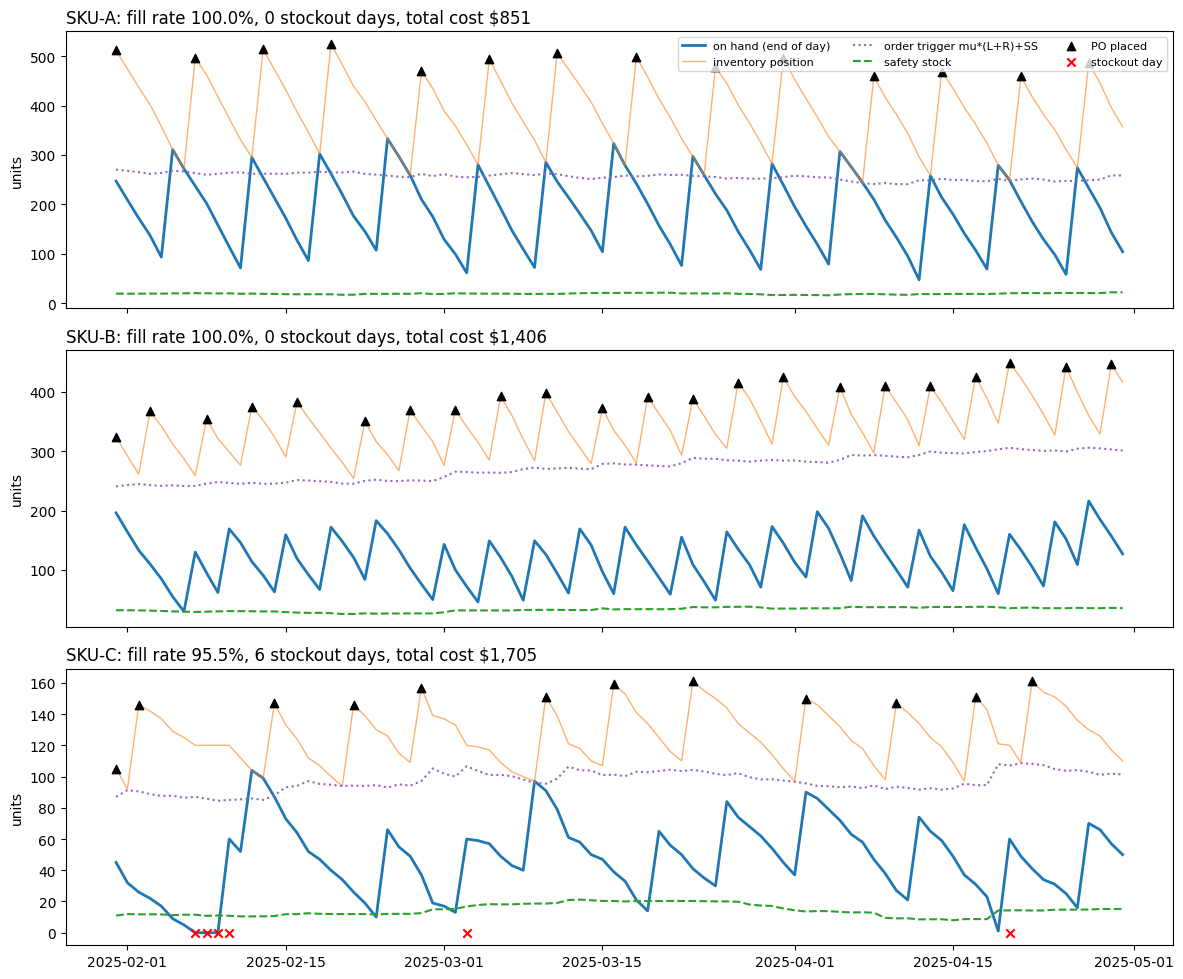

In [13]:
fig, axes = plt.subplots(len(SKUS), 1, figsize=(12, 3.3 * len(SKUS)), sharex=True)
for ax, sku in zip(axes, SKUS):
    d = result.daily[result.daily["sku"] == sku].set_index("date")
    dec = result.decisions[result.decisions["sku"] == sku].set_index("date")
    ax.plot(d.index, d["on_hand_end"], lw=2, label="on hand (end of day)")
    ax.plot(d.index, d["inv_position"], lw=1, alpha=0.6, label="inventory position")
    ax.plot(dec.index, dec["order_trigger"], ":", color="tab:purple", label="order trigger mu*(L+R)+SS")
    ax.plot(dec.index, dec["safety_stock"], "--", color="tab:green", label="safety stock")
    orders = d[d["ordered"] > 0]
    ax.scatter(orders.index, orders["inv_position"], marker="^", color="black", zorder=5, label="PO placed")
    so = d[d["lost"] > 0]
    ax.scatter(so.index, np.zeros(len(so)), marker="x", color="red", zorder=5, label="stockout day")
    k = agent_kpis.loc[sku]
    ax.set_title(f"{sku}: fill rate {k.fill_rate:.1%}, {int(k.stockout_days)} stockout days, total cost ${k.total_cost:,.0f}", loc="left")
    ax.set_ylabel("units")
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
plt.tight_layout()

### 7.1 Does the agent beat simpler policies?

Same data, same costs, same MOQ/EOQ rules. Only the forecast or the safety-stock logic changes:

* **EWMA + SS (agent)**: the policy above
* **Naive + SS**: forecast = yesterday's demand
* **EWMA, no SS**: orders only when projected stock would go below zero
* **Naive, no SS**

In [14]:
policies = {
    "EWMA + SS (agent)": dict(forecaster_factory=ewma_factory, use_safety_stock=True),
    "Naive + SS": dict(forecaster_factory=naive_factory, use_safety_stock=True),
    "EWMA, no SS": dict(forecaster_factory=ewma_factory, use_safety_stock=False),
    "Naive, no SS": dict(forecaster_factory=naive_factory, use_safety_stock=False),
}
comparison, fill_by_sku = {}, {}
for name, kw in policies.items():
    k = kpis(simulate(demand, params, inventory, **kw).daily)
    comparison[name] = k.loc["TOTAL", ["fill_rate", "cycle_service", "lost_units", "stockout_days", "n_POs",
                                       "avg_on_hand", "holding_cost", "stockout_cost", "order_cost", "total_cost"]]
    fill_by_sku[name] = k.loc[SKUS, "fill_rate"]

comparison = pd.DataFrame(comparison).T
display(comparison.astype(float).round(3))
print("Fill rate by SKU:")
display(pd.DataFrame(fill_by_sku).T.round(4))

,fill_rate,cycle_service,lost_units,stockout_days,n_POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost
EWMA + SS (agent),0.996,0.978,31.0,6.0,48.0,350.933,1985.96,775.0,1200.0,3960.96
Naive + SS,0.994,0.974,42.0,7.0,44.0,450.600,2879.18,637.0,1100.0,4616.18
"EWMA, no SS",0.981,0.933,136.0,18.0,47.0,304.244,1650.12,2373.0,1175.0,5198.12
"Naive, no SS",0.977,0.952,164.0,13.0,42.0,395.978,2529.01,2151.0,1050.0,5730.01


Fill rate by SKU:


sku,SKU-A,SKU-B,SKU-C
EWMA + SS (agent),1.0000,1.0000,0.9551
Naive + SS,0.9944,0.9996,0.9696
"EWMA, no SS",1.0000,0.9721,0.9175
"Naive, no SS",0.9932,0.9601,0.9609


### 7.2 Robustness: 20 fresh demand scenarios

A single 90-day run is noisy: a few promo spikes can decide the ranking. Here the same generator draws 20 *new* demand histories (different seeds, same SKUs, params and opening stock), and every policy runs on each one. The averages below are a fairer comparison. This section only runs on the built-in synthetic SKUs.

Mean over 20 scenarios (agent_wins_% = share of scenarios where the agent's total cost <= that policy's):


,fill_rate,cycle_service,lost_units,n_POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost,total_cost_sd,agent_wins_%
policy,,,,,,,,,,,
EWMA + SS (agent),0.993,0.975,46.55,47.90,369.514,2169.028,1073.25,1197.50,4439.778,586.548,100.0
Naive + SS,0.993,0.976,53.00,41.90,510.919,3552.084,1102.05,1047.50,5701.634,1029.952,100.0
"EWMA, no SS",0.976,0.932,168.25,46.35,309.020,1738.977,2711.80,1158.75,5609.527,654.141,100.0
"Naive, no SS",0.975,0.948,178.50,40.15,433.441,2987.850,2469.85,1003.75,6461.450,1011.788,100.0


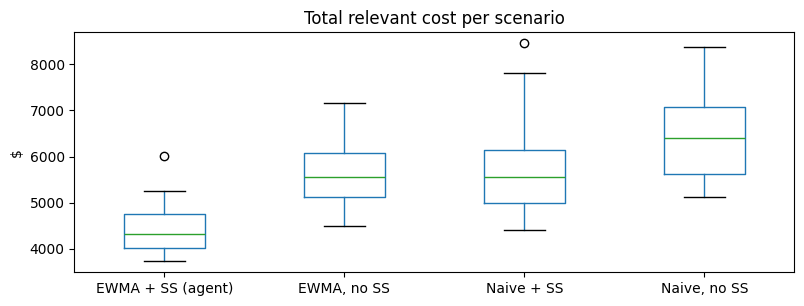

In [15]:
N_SCENARIOS = 20
SWEEP_LEVELS = [0.50, 0.80, 0.90, 0.95, 0.97, 0.99, 0.995]
METRICS = ["fill_rate", "cycle_service", "lost_units", "n_POs", "avg_on_hand",
           "holding_cost", "stockout_cost", "order_cost", "total_cost"]

if set(SKUS) == {"SKU-A", "SKU-B", "SKU-C"}:
    policy_runs, sweep_runs = [], []
    for s in range(N_SCENARIOS):
        dem = aggregate_daily(make_synthetic_data(seed=1000 + s)[0], SKUS).fillna(0).astype(int)
        for name, kw in policies.items():
            k = kpis(simulate(dem, params, inventory, **kw).daily).loc["TOTAL"]
            policy_runs.append({"scenario": s, "policy": name, **k[METRICS].to_dict()})
        for sl in SWEEP_LEVELS:
            k = kpis(simulate(dem, params.assign(service_level=sl), inventory).daily).loc["TOTAL"]
            sweep_runs.append({"scenario": s, "service_level": sl, **k[METRICS].to_dict()})
    policy_runs, sweep_runs = pd.DataFrame(policy_runs), pd.DataFrame(sweep_runs)

    robust = policy_runs.groupby("policy", sort=False)[METRICS].mean()
    robust["total_cost_sd"] = policy_runs.groupby("policy", sort=False)["total_cost"].std()
    cost = policy_runs.pivot(index="scenario", columns="policy", values="total_cost")
    robust["agent_wins_%"] = 100 * cost.apply(lambda col: (cost["EWMA + SS (agent)"] <= col).mean())
    print(f"Mean over {N_SCENARIOS} scenarios (agent_wins_% = share of scenarios where the agent's total cost <= that policy's):")
    display(robust.round(3))

    fig, ax = plt.subplots(figsize=(9, 3.2))
    policy_runs.boxplot(column="total_cost", by="policy", ax=ax, grid=False)
    ax.set_title("Total relevant cost per scenario"); ax.set_xlabel(""); ax.set_ylabel("$")
    plt.suptitle("")
else:
    print("Custom SKUs detected: skipping the synthetic-scenario robustness check.")

### 7.3 Service-level trade-off

Sweep the target service level (applied to all SKUs) over the same 20 scenarios, to see how much fill rate each extra point of service costs in holding.

,fill_rate,cycle_service,lost_units,n_POs,avg_on_hand,holding_cost,stockout_cost,order_cost,total_cost
service_level,,,,,,,,,
0.500,0.976,0.932,168.25,46.35,309.020,1738.977,2711.80,1158.75,5609.527
0.800,0.989,0.961,77.55,47.35,336.818,1945.270,1454.45,1183.75,4583.470
0.900,0.993,0.971,52.40,47.80,356.463,2093.155,1136.80,1195.00,4424.956
0.950,0.993,0.976,46.40,47.90,370.349,2201.571,1033.10,1197.50,4432.170
0.970,0.994,0.979,42.40,47.90,380.728,2274.852,991.50,1197.50,4463.852
0.990,0.995,0.981,38.85,47.90,399.429,2414.098,934.20,1197.50,4545.798
0.995,0.995,0.981,38.70,47.90,410.681,2496.514,933.70,1197.50,4627.714


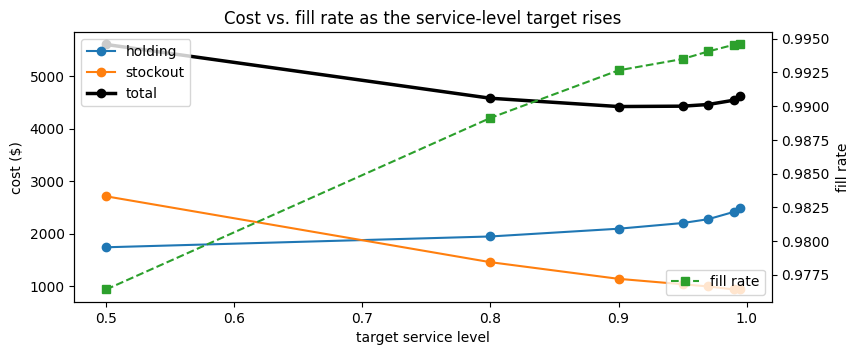

In [16]:
if set(SKUS) == {"SKU-A", "SKU-B", "SKU-C"}:
    sweep = sweep_runs.groupby("service_level")[METRICS].mean()
else:  # fall back to the single historical run
    sweep = pd.DataFrame([
        {"service_level": sl, **kpis(simulate(demand, params.assign(service_level=sl), inventory).daily).loc["TOTAL", METRICS].to_dict()}
        for sl in SWEEP_LEVELS]).set_index("service_level")
display(sweep.round(3))

fig, ax1 = plt.subplots(figsize=(9, 3.5))
ax1.plot(sweep.index, sweep["holding_cost"], "o-", label="holding")
ax1.plot(sweep.index, sweep["stockout_cost"], "o-", label="stockout")
ax1.plot(sweep.index, sweep["total_cost"], "o-", lw=2.5, color="black", label="total")
ax1.set_xlabel("target service level"); ax1.set_ylabel("cost ($)")
ax2 = ax1.twinx()
ax2.plot(sweep.index, sweep["fill_rate"], "s--", color="tab:green", label="fill rate")
ax2.set_ylabel("fill rate")
ax1.legend(loc="upper left"); ax2.legend(loc="lower right")
ax1.set_title("Cost vs. fill rate as the service-level target rises");

## 8. Optional: LLM operations briefing (Gemini)

The replenishment decisions above are deterministic and need no API. This optional step hands the KPI table and the agent's exception log (orders and warnings) to Gemini, which drafts a short briefing for a planner. The LLM only *narrates*: it never changes an order.

**API key.** The key is read from the secret named **`GEMINI_API_KEY`**.
* **Colab:** click the key icon in the left sidebar, add a secret named `GEMINI_API_KEY`, and toggle *Notebook access* on.
* **Local:** set an environment variable `GEMINI_API_KEY`.

Without the key the cell prints a note and skips, so *Run all* still completes.

In [17]:
GEMINI_MODEL = "gemini-2.5-flash"


def get_gemini_key():
    """Colab secret GEMINI_API_KEY first, then the GEMINI_API_KEY environment variable."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GEMINI_API_KEY")
        except Exception as e:  # secret missing or notebook access not granted
            print(f"Colab secret GEMINI_API_KEY unavailable ({type(e).__name__}).")
    return os.environ.get("GEMINI_API_KEY")


def build_briefing_prompt(result: SimResult, kpi_table: pd.DataFrame) -> str:
    d = result.decisions
    exceptions = d[(d["action"] == "ORDER") | d["rationale"].str.contains("WARNING")]
    log_lines = [f"{r.date:%Y-%m-%d} {r.sku} {r.action} {r.qty}: {r.rationale}" for r in exceptions.itertuples()]
    return f"""You are a supply-chain analyst reviewing a 90-day simulation of an inventory replenishment agent.
Use only the numbers below; do not invent data.

SKU parameters:
{params.to_string()}

Outcome KPIs (fill_rate = served/demand, cycle_service = share of days without stockout, costs in $):
{kpi_table.round(3).to_string()}

Agent decision log (orders and warnings only):
{chr(10).join(log_lines[:200])}

Write a briefing for an inventory planner, at most 250 words, in Markdown:
1. Performance against each SKU's service-level target.
2. What drove the stockouts and the largest cost lines, per SKU.
3. Two or three concrete parameter changes (MOQ, service level, review period, opening stock, supplier lead time) with the trade-off each one implies."""


api_key = get_gemini_key()
if not api_key:
    print("GEMINI_API_KEY not set: skipping the optional LLM briefing (the agent itself does not need it).")
else:
    try:
        from google import genai
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "google-genai"])
        from google import genai
    try:
        client = genai.Client(api_key=api_key)
        response = client.models.generate_content(model=GEMINI_MODEL, contents=build_briefing_prompt(result, agent_kpis))
        display(Markdown(response.text))
    except Exception as e:
        print(f"Gemini call failed ({type(e).__name__}: {e}); the rest of the notebook is unaffected.")

Gemini call failed (ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).', 'status': 'NOT_FOUND'}}); the rest of the notebook is unaffected.


## 9. Findings, assumptions & next steps

**Findings** (default data, seed 42; numbers will differ if you change the data)

* **The agent hits its targets on SKU-A and SKU-B.** Both reach a 100% fill rate with no stockout days, while carrying only about 4–5 days of average stock.
* **SKU-C's shortfall is mostly structural.** Opening stock (50) covers about 7 days, but the lead time is 10. On its very first review the agent flags the Feb 7–10 stockout as *unavoidable, needs an expedite* and orders anyway for what comes after. Those 4 days are two-thirds of SKU-C's stockout days. The remaining 2 come from promo spikes, which a 90% target with a small $\sigma_e$ only partly buffers.
* **Projecting over the right window matters.** An earlier version of this agent reacted to dips *inside* the lead time and ordered every day. It placed redundant POs and roughly doubled total cost. Limiting the trigger to the days a new PO can actually protect fixed that.
* **Both the forecast and the safety stock pay off.** Over 20 fresh demand scenarios, the agent (EWMA + SS) had the lowest total cost in every scenario. Mean costs: agent ~$4.4k, naive + SS ~$5.7k, EWMA without SS ~$5.6k, naive without SS ~$6.5k. EWMA cuts holding cost, because a smoother forecast means less inflated stock. Safety stock cuts lost sales about 3.6x.
* **The service-level curve is flat near the top.** Mean total cost bottoms out around a 90–95% target. Above that, holding cost climbs faster than the stockout cost it saves, and fill rate gains only a few tenths of a percent.
* **MOQ and EOQ drive order size.** Required quantities are usually small. With a $25 PO cost, EOQ sets the size for SKU-A and SKU-B, and MOQ for SKU-C.

**Assumptions / simplifications**

* **Lost sales, not backorders.** Unmet demand is gone. `qty_sold` is treated as true demand; in real data, sales during a stockout are *censored* and would understate demand.
* EWMA gives a flat level, with no explicit trend or weekly seasonality. That error is absorbed into $\sigma_e$, so SKU-B ends up with a larger safety stock rather than a smarter forecast.
* Forecast errors are assumed i.i.d. normal, so $\sigma$ scales with $\sqrt{L+R}$. Lead times are deterministic, and suppliers have unlimited capacity.
* The fixed order cost is one constant for every SKU (`ORDER_COST_PER_PO`). Set it to 0 to disable the EOQ term.

**Possible extensions**: Holt-Winters or a day-of-week-aware forecast for SKU-B; stochastic lead times (add $\hat\mu^2\sigma_L^2$ to the variance); a cost-optimal service level from the critical ratio; an LLM layer that reads the log and drafts supplier emails or exception reports.